# 03 · Signatures — embryonic-development module scores & Gate 2

The three embryonic modules (**Gast** gastrulation, **pSom** posterior somitogenesis,
**Crest** neural crest) were scored in 02 against the shared **union** control pool and
graph-smoothed. Here we render them as deliverables and evaluate **Gate 2**.

**Gate 2 (verdict: NO-GO — pattern absent at single-cell resolution).** The non-branching
GO case (§1–2) requires the programs to be *present*: Gast/pSom overlapping or organised
along the axis with **Crest as an inverse/terminal gradient**. On this 818-cell SmartSeq2
manifold the developmental geography is **not present in the raw per-cell scores** and appears
only after graph-smoothing — and a permutation null (below) shows that smoothed structure is
indistinguishable from what smoothing manufactures from random scores on this same graph.
Raw Gast↔pSom = −0.02 (no cross-repression); the smoothed −0.77 is a smoothing amplification
that a permuted null reproduces (95% CI ≈ ±0.7). The defining terminal-Crest gradient
(smoothed ρ≈+0.73) is **not** significant against the null (p≈0.14). Per §2 ("NO-GO where the
pattern is absent"), Gate 2 = **NO-GO**. The unconditional EMT-TF expression step still follows
as notebook 04.

In [ ]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [ ]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load the rooted manifold (signatures scored + smoothed in 02)

In [ ]:
adata = sc.read_h5ad(os.path.join(pth_out, 'manifold.h5ad'))
modules = {'Gast':'Gastrulation', 'pSom':'Somitogenesis', 'Crest':'Neural Crest'}
print('cells:', adata.shape[0], '| scores present:', [m for m in modules if m in adata.obs])
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
for src,lab in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    print(f'{lab}: {g.size}/{feat[src].size} genes present | mean {adata.obs[lab].mean():+.3f}')

cells: 818 | scores present: ['Gast', 'pSom', 'Crest']
Gast: 71/81 genes present | mean -0.067
pSom: 89/98 genes present | mean +0.098
Crest: 98/104 genes present | mean -0.056


### Gate 2 — module geography on the manifold (with a smoothing null)
The apparent geography lives only in the graph-smoothed scores, so the decisive test is
whether that smoothed structure exceeds a **permutation null**: permute each raw per-cell
score across cells and re-smooth on the same kNN graph (which itself was built from these
genes), then compare. Read on smoothed scores for the point estimate, but judge against the
null. Deliverable signature UMAPs below show the **raw** scores — the honest single-cell view.

In [ ]:
print('smoothed spatial correlations (geography):')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    r = np.corrcoef(adata.obs[a], adata.obs[b])[0,1]; print(f'  {a} vs {b}: r = {r:+.2f}')
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('gradient along pseudotime (Spearman rho on smoothed):')
for s in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,_ = spearmanr(t, adata.obs[s]); print(f'  {s}: rho = {rho:+.3f}')
hi = adata.obs['Crest_sm'] >= adata.obs['Crest_sm'].quantile(0.9)
print(f'Neural-crest-high decile mean pseudotime = {tn[hi.values].mean():.2f} (terminal if ~1)')

# --- permutation null: is the smoothed geography more than a smoothing artifact? ---
import scipy.sparse as sp
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.asarray(A.sum(1)).ravel()) @ A
def _smooth(v, k=3):
    x = v.astype(float).copy()
    for _ in range(k): x = A @ x
    return np.asarray(x).ravel()
rng = np.random.default_rng(0)
G = adata.obs['Gast'].values.astype(float); P = adata.obs['pSom'].values.astype(float); C = adata.obs['Crest'].values.astype(float)
real_gp = np.corrcoef(_smooth(G), _smooth(P))[0,1]
real_cpt = spearmanr(t, _smooth(C))[0]
N = 500; null_gp = np.empty(N); null_cpt = np.empty(N)
for i in range(N):
    null_gp[i]  = np.corrcoef(_smooth(G[rng.permutation(G.size)]), _smooth(P[rng.permutation(P.size)]))[0,1]
    null_cpt[i] = spearmanr(t, _smooth(C[rng.permutation(C.size)]))[0]
p_gp  = (np.sum(np.abs(null_gp)  >= abs(real_gp))  + 1)/(N+1)
p_cpt = (np.sum(np.abs(null_cpt) >= abs(real_cpt)) + 1)/(N+1)
print('raw Gast<->pSom r = %+.2f (single-cell: no cross-repression)' % np.corrcoef(G,P)[0,1])
print('permutation null (n=%d): smoothing random scores on this graph gives 95%% CI [%.2f, %.2f]'
      % (N, *np.percentile(null_gp,[2.5,97.5])))
print('  Gast<->pSom smoothed  = %+.2f | null p = %.3f' % (real_gp, p_gp))
print('  Crest~pseudotime rho  = %+.2f | null p = %.3f (defining terminal gradient — NOT significant)' % (real_cpt, p_cpt))
print('\nGate 2 = NO-GO: the developmental pattern is absent in raw scores and the smoothed')
print('geography is not distinguishable from a smoothing artifact (terminal-Crest gradient p=%.2f).' % p_cpt)


smoothed spatial correlations (geography):
  Gast_sm vs pSom_sm: r = -0.77
  Crest_sm vs Gast_sm: r = +0.30
  Crest_sm vs pSom_sm: r = -0.35
gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho = +0.043
  pSom_sm: rho = +0.239
  Crest_sm: rho = +0.727
Neural-crest-high decile mean pseudotime = 1.00 (terminal if ~1)
raw Gast<->pSom r = -0.02 (single-cell: no cross-repression)
permutation null (n=500): smoothing random scores on this graph gives 95% CI [-0.69, 0.63]
  Gast<->pSom smoothed  = -0.77 | null p = 0.016
  Crest~pseudotime rho  = +0.73 | null p = 0.136 (defining terminal gradient — NOT significant)

Gate 2 = NO-GO: the developmental pattern is absent in raw scores and the smoothed
geography is not distinguishable from a smoothing artifact (terminal-Crest gradient p=0.14).


### Module maps preview (house linear layout)

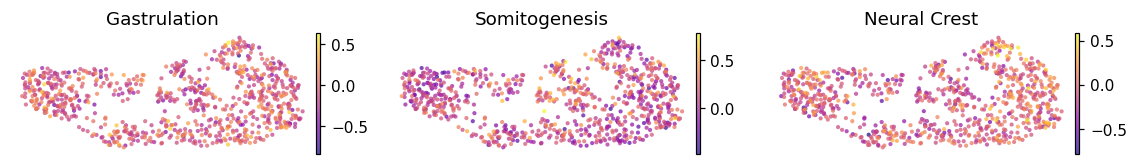

In [ ]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
fig, axes = plt.subplots(1, 3, figsize=(10.5,1.6))
for ax,(m,title) in zip(axes, modules.items()):
    sc.pl.umap(plot, color=m, cmap='plasma', alpha=.7, size=30, colorbar_loc='right',
               frameon=False, show=False, ax=ax, title=title)
    ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
fig.tight_layout()

### Per-module signature figures + colorbars (deliverable)
House style: `figsize=(3.5,1.5)`, pseudotime left→right, `size=30`, plasma, **raw** (not
smoothed) score per cell so real per-cell spread is visible (§ Gate-3 spec: show raw scores
in the deliverable signature UMAPs). Colorbar ticks data-driven.

saved Gast_signature.pdf + colorbar
saved pSom_signature.pdf + colorbar
saved Crest_signature.pdf + colorbar


<ipython-input-6-787382e479a7>:16: UserWarning: Adding colorbar to a different Figure <Figure size 350x150 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.
  cb = plt.colorbar(ax.collections[0], cax=cax); cb.ax.tick_params(which='both', size=0)
<ipython-input-6-787382e479a7>:16: UserWarning: Adding colorbar to a different Figure <Figure size 350x150 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.
  cb = plt.colorbar(ax.collections[0], cax=cax); cb.ax.tick_params(which='both', size=0)
<ipython-input-6-787382e479a7>:16: UserWarning: Adding colorbar to a different Figure <Figure size 350x150 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.
  cb = plt.colorbar(ax.collections[0], cax=cax); cb.ax.tick_params(which='both', size=0)


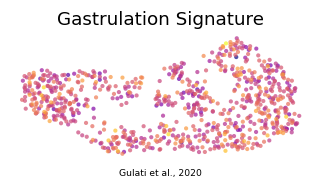

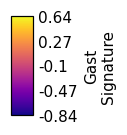

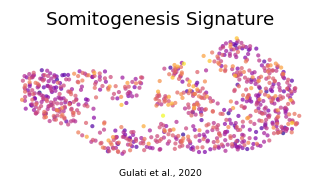

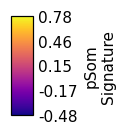

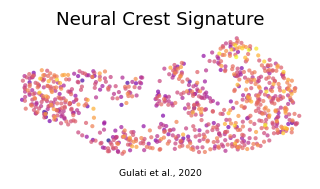

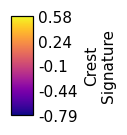

In [ ]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
titles = {'Gast':'Gastrulation Signature','pSom':'Somitogenesis Signature','Crest':'Neural Crest Signature'}
for m in ['Gast','pSom','Crest']:
    fig, ax = plt.subplots(figsize=(3.5,1.5))
    sc.pl.umap(plot, color=m, cmap='plasma', alpha=.7, size=30, colorbar_loc=None,
               frameon=False, show=False, ax=ax, title=titles[m])
    ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
    ax.text(.5,-.12,'Gulati et al., 2020', ha='center', transform=ax.transAxes, size=6)
    fig.savefig(os.path.join(pth_fig, f'{m}_signature.pdf'), bbox_inches='tight')
    lo, hi = float(adata.obs[m].min()), float(adata.obs[m].max())
    ticks = np.round(np.linspace(lo, hi, 5), 2)
    fcb = plt.figure(figsize=(.66,1)); cax = fcb.add_axes([.35,.05,.3,.9])
    cb = plt.colorbar(ax.collections[0], cax=cax); cb.ax.tick_params(which='both', size=0)
    cb.set_label(f'{m}\nSignature'); cb.set_ticks(ticks, labels=ticks); cb.solids.set_alpha(1)
    fcb.savefig(os.path.join(pth_cb, f'{m}_colorbar.pdf'), bbox_inches='tight')
    print('saved', f'{m}_signature.pdf', '+ colorbar')

### Save signatures data

In [ ]:
adata.write(os.path.join(pth_out, 'signatures.h5ad'))
print('saved signatures.h5ad', adata.shape)

saved signatures.h5ad (818, 28226)
